# K-Means

**Review 2 - Clustering - no target labels used in fitting**

The 4,009-row used-car dataset is segmented using car age, log price and log mileage.
Training-only preprocessing and five-fold validation choose the model configuration; a separate
20% holdout checks assignment quality. PCA and t-SNE are visualizations, not fitting inputs.

## 1. Imports

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook inside the project or project/notebooks folder.")
sys.path.insert(0, str(ROOT))

from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from src.clustering import *


## 2. Dataset audit and preprocessing

In [2]:
raw, df, train, test = load_data()
display(raw.dtypes.to_frame("dtype").astype(str))
display(raw.isna().sum().to_frame("Missing raw values"))
print("Raw / cleaned / train / holdout:", len(raw), len(df), len(train), len(test))
print("Exact duplicates removed:", len(raw) - len(df))
display(train[["price_usd", "mileage_miles", "car_age"]].describe())
assert set(train.index).isdisjoint(test.index)

Raw / cleaned / train / holdout: 4009 4009 3207 802
Exact duplicates removed: 0


,dtype
brand,object
model,object
model_year,int64
milage,object
fuel_type,object
engine,object
transmission,object
ext_col,object
int_col,object
accident,object


,Missing raw values
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,113


,price_usd,mileage_miles,car_age
count,3207.0,3207.0,3207.000000
mean,43125.756782,64942.199563,10.442158
std,51204.51605,52433.516741,6.032533
min,2000.0,100.0,2.000000
25%,17050.0,23319.5,6.000000
50%,31300.0,53500.0,9.000000
75%,49999.0,93985.5,14.000000
max,749950.0,405000.0,52.000000


## 3. Required EDA

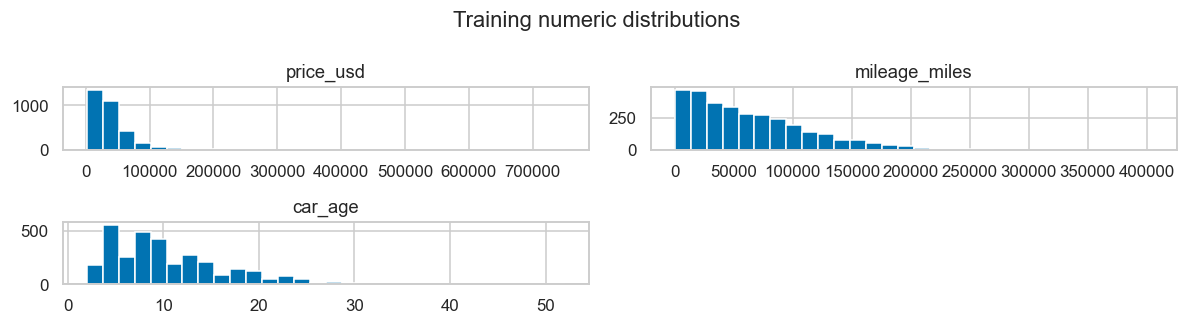

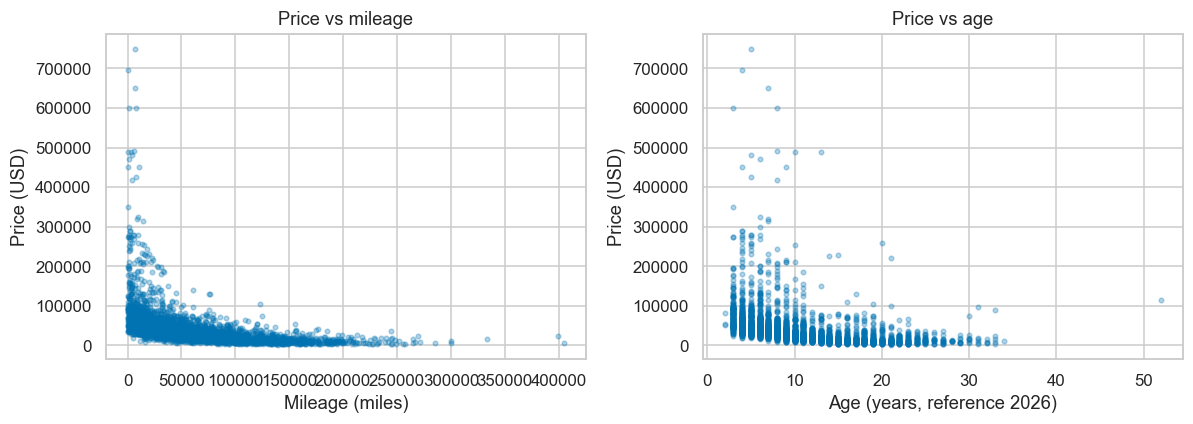

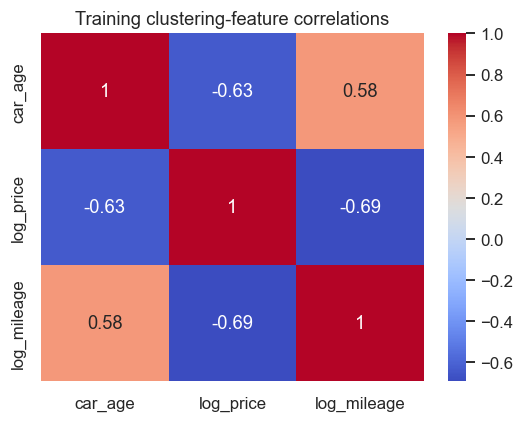

,IQR outliers retained
price_usd,191
mileage_miles,58
car_age,52


In [3]:
train[["price_usd", "mileage_miles", "car_age"]].hist(
    bins=30, figsize=(11, 3)
)
plt.suptitle("Training numeric distributions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(train.mileage_miles, train.price_usd, alpha=0.3, s=9)
axes[0].set(
    xlabel="Mileage (miles)", ylabel="Price (USD)", title="Price vs mileage"
)
axes[1].scatter(train.car_age, train.price_usd, alpha=0.3, s=9)
axes[1].set(
    xlabel="Age (years, reference 2026)",
    ylabel="Price (USD)",
    title="Price vs age",
)
plt.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(5, 4))
sns.heatmap(
    ClusterFeatures().transform(train).corr(), annot=True, cmap="coolwarm", ax=axis
)
axis.set_title("Training clustering-feature correlations")
plt.tight_layout()
plt.show()

numeric = train[["price_usd", "mileage_miles", "car_age"]]
iqr = numeric.quantile(0.75) - numeric.quantile(0.25)
outlier_counts = (
    (numeric < numeric.quantile(0.25) - 1.5 * iqr)
    | (numeric > numeric.quantile(0.75) + 1.5 * iqr)
).sum()
display(outlier_counts.to_frame("IQR outliers retained"))

## 4. Model training and tuning

Candidates are selected using mean five-fold validation silhouette. Higher silhouette and Calinski-Harabasz are better; lower Davies-Bouldin is better.

In [4]:
kind = "kmeans"
if kind == "kmeans":
    print("Baseline: k=3 | Search: k=2 through 6")
    print("Validation assignment: native K-Means prediction")
else:
    print("Baseline: k=3 with Ward linkage")
    print("Search: k=2 through 6 with Ward, complete and average linkage")
    print("Validation assignment: nearest-training-centroid proxy")

Baseline: k=3 | Search: k=2 through 6
Validation assignment: native K-Means prediction


In [5]:
search_summary, fold_results, best = tune(kind, train)
display(search_summary.sort_values("CV_silhouette", ascending=False))
print("Chosen on training folds only:", best)

output_dir = ROOT / "results" / kind
output_dir.mkdir(parents=True, exist_ok=True)
fold_results.to_csv(output_dir / "cv_fold_results.csv", index=False)

Chosen on training folds only: {'k': 2, 'linkage': 'ward'}


,k,linkage,CV_silhouette,CV_silhouette_std,CV_Davies_Bouldin,CV_Calinski_Harabasz,valid_folds,min_represented_clusters,eligible
0,2,ward,0.420253,0.011829,0.879059,621.140018,5,2,True
1,3,ward,0.371093,0.009430,0.899588,592.816247,5,3,True
2,4,ward,0.335625,0.010001,0.940295,557.666316,5,4,True
4,6,ward,0.297278,0.007367,1.020477,475.131255,5,6,True
3,5,ward,0.286414,0.007896,1.065332,501.183835,5,5,True


## 5. Evaluation

In [6]:
comparison, fitted, prep, X, X_holdout, pca, profiles = fit_compare(
    kind, train, test, search_summary, best
)
display(comparison.round(4))

metric_columns = [
    "Silhouette",
    "Davies_Bouldin",
    "Calinski_Harabasz",
    "CV_silhouette",
    "Holdout_Silhouette",
]
display(
    (comparison.loc[1, metric_columns] - comparison.loc[0, metric_columns]).to_frame(
        "After minus before"
    )
)
display(profiles)

,Model,Stage,k,linkage,Silhouette,Davies_Bouldin,Calinski_Harabasz,CV_silhouette,CV_silhouette_std,Holdout_Silhouette,Holdout_Davies_Bouldin,Holdout_Calinski_Harabasz
0,K-Means,Before tuning,3,not applicable,0.3730,0.8993,2992.6547,0.3711,0.0094,0.3703,0.9268,706.2894
1,K-Means,After tuning,2,not applicable,0.4234,0.8806,3120.8159,0.4203,0.0118,0.4147,0.8965,732.3490


,After minus before
Silhouette,0.050417
Davies_Bouldin,-0.018774
Calinski_Harabasz,128.161239
CV_silhouette,0.049159
Holdout_Silhouette,0.044322


,cars,median_price_usd,median_mileage_miles,median_age
cluster,,,,
0,1490,16489.0,96274.0,14.0
1,1717,47500.0,25882.0,6.0


## 6. Required visualizations and cluster interpretation

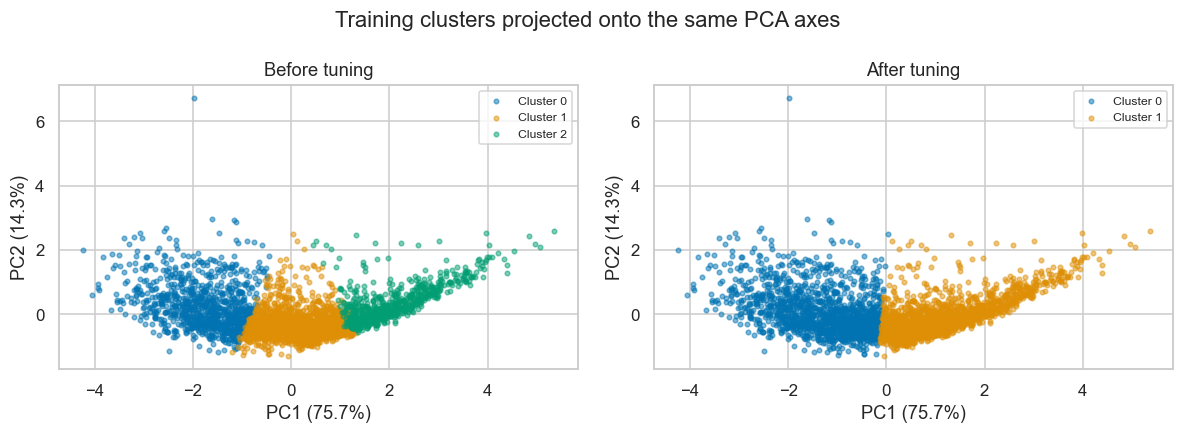

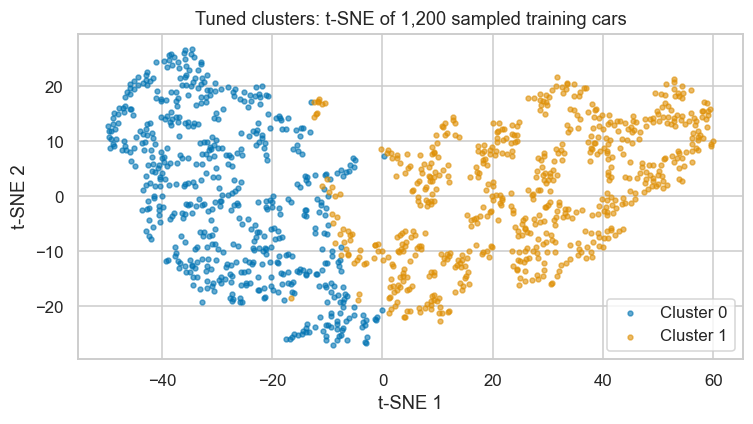

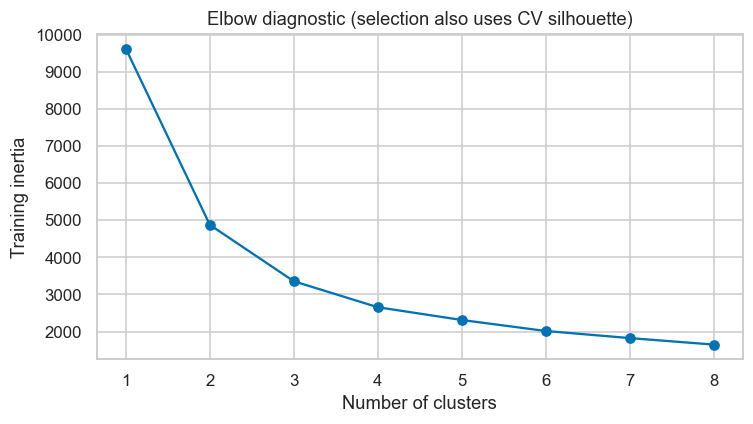

In [7]:
plot_clusters(kind, fitted, X, pca)


## 7. Observation / Interpretation

Complete these observations using the executed evidence:

- Describe the age, mileage and price profile of each cluster.
- Explain whether the elbow or dendrogram supports the selected number of clusters.
- Compare silhouette, Davies-Bouldin and Calinski-Harabasz before and after tuning.
- Discuss the three-feature limitation and the arbitrary nature of cluster numbers.
- For hierarchical clustering, explain the centroid-proxy limitation for unseen cars.
- Treat t-SNE as a visualization only and do not describe clusters as known ground-truth classes.